In [1]:
if (!require("Require")) {install.packages("Require"); require("Require")}
Require(c("tidyverse", "maps", "geosphere", "mapproj", "ggnewscale", "patchwork", "ggtext"))

Loading required package: Require

Warning message:
“package ‘Require’ was built under R version 4.5.2”

✔ Updated metadata database: 8.28 MB in 4 files.


ℹ Updating metadata database
✔ Updating metadata database ... done


 

→ Package library at /Library/Frameworks/R.framework/Versions/4.5-arm64/Resources/library.

ℹ No downloads are needed

✔ 1 pkg:  s]

pak install strategy 'identify-and-defer' took 0.3s for 1 requested ref(s)

Loading required package: geosphere

Loading required package: ggnewscale

Loading required package: ggtext

Loading required package: mapproj

Loading required package: maps

Loading required package: patchwork

Loading required package: tidyverse

── Attaching core tidyverse packages ────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ──────────────────────────────

In [2]:
costs <- read_csv("costs.csv")
gates <- read_csv("gates.csv")
transactions <- read_csv("transactions.csv")

Rows: 115204 Columns: 7
── Column specification ──────────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): Cost_ID, Cost_Type, Route_ID, From, To
dbl  (1): Amount
dttm (1): Cost_Date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 112 Columns: 5
── Column specification ──────────────────────────────────────────────────────────────
Delimiter: ","
chr (4): City, Gate_Number, Route_ID, Year
num (1): Annual_Gate_Cost

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 559985 Columns: 9
── Column specification ──────────────────────────────────────────────────────────────
Delimiter: ","
chr (9): Transaction_ID, Booking_ID, Transaction_Date, Route_ID, Transaction...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Speci

Cleaning costs dataset

In [16]:
costs <- costs |>
    mutate(Route_ID = toupper(Route_ID))
first <- str_extract(costs$Route_ID, "[A-Z]{3}")
second <- str_extract(costs$Route_ID, "[A-Z]{3}$")
combined <- paste0(first, '-', second)
costs$Route_ID = combined
duplicated(costs) |> sum()
#costs

[1] 0

Cleaning gates dataset

In [18]:
gates <- gates |>
    mutate(Route_ID = toupper(Route_ID))
first <- str_extract(gates$Route_ID, "[A-Z]{3}")
second <- str_extract(gates$Route_ID, "[A-Z]{3}$")
combined <- paste0(first, '-', second)
gates$Route_ID = combined
duplicated(gates) |> sum()
#gates

[1] 0

Cleaning transactions dataset

In [21]:
transactions <- transactions |>
    mutate(Route_ID = toupper(Route_ID)) |>
    mutate(Booking_Channel = toupper(Booking_Channel)) |>
    mutate(Transaction_Type = toupper(Transaction_Type)) |>
    mutate(Payment_Method = toupper(Payment_Method))
first <- str_extract(transactions$Route_ID, "[A-Z]{3}")
second <- str_extract(transactions$Route_ID, "[A-Z]{3}$")
combined <- paste0(first, '-', second)
transactions$Route_ID = combined

# transactions$Transaction_Date <- format(
#         as.Date(parse_date_time(
#           as.character(transactions$Transaction_Date),
#           orders = c("ymd HM", "mdy HM", "dmy HM")
#         )), 
#     "%Y-%m-%d %H:%M")

# keep Transaction_Date as Date-Time data type
transactions$Transaction_Date <- parse_date_time(
  as.character(transactions$Transaction_Date),
  orders = c("ymd HM", "mdy HM", "dmy HM")
)

transactions$Amount <- as.numeric(str_replace(str_replace(transactions$Amount, "\\$", ""), ",", ""))
transactions <- distinct(transactions)
duplicated(transactions) |> sum()
#transactions

[1] 0

Transaction_ID,Booking_ID,Transaction_Date,Route_ID,Transaction_Type,Membership_Tier,Booking_Channel,Payment_Method,Amount
<chr>,<chr>,<dttm>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
TX1525667,BK396819,NA,YYZ-YHZ,TICKET,Non-Member,DIRECT WEB,CREDIT CARD,954.80
TX1420893,BK245942,NA,YVR-YEG,TICKET,Blue,CORPORATE PORTAL,CREDIT CARD,971.17
TX1313706,BK274024,NA,YVR-YEG,FOOD & ONBOARD,Non-Member,ONLINE TRAVEL AGENCY,CREDIT CARD,9.87
TX1169582,BK374084,NA,YYT-YHZ,TICKET,Silver,DIRECT WEB,CREDIT CARD,744.61
TX1378465,BK319834,NA,YYZ-YYC,TICKET,Blue,DIRECT WEB,CREDIT CARD,1380.38
TX1133037,BK382994,NA,YQB-YUL,EXTRA BAGGAGE,Blue,DIRECT WEB,CREDIT CARD,45.06
TX1112418,BK332533,NA,YHZ-YYZ,CHANGE FEE,Blue,DIRECT WEB,POINTS + CASH,75.00
TX1363471,BK329720,NA,YWG-YYC,TICKET,Non-Member,CORPORATE PORTAL,CREDIT CARD,1231.75
TX1413482,BK440357,NA,YYC-YVR,TICKET,Blue,MOBILE APP,CREDIT CARD,837.35


## Question 1 - Easy
#### Statement
How did NorthByte's revenue and costs change between FY2024-25 and FY2025-26? When did NorthByte's results start to decline, and which changes explain most of the drop?
#### Meeting Notes
**Revenue and cost changes:** Plot revenue and costs by month across the two fiscal years to identify when performance declined and which costs drove the drop. Fuel, crew, maintenance, and gate leases were raised for examination. The team wanted to recreate and check the AI-generated figures against the data.
- Hit each transaction type and cost type, and graph in a way that makes them easy to compare year to year
#### Conclusion

# A tibble: 24 × 9
   Actual_Date Total_Amount Total_Amount_M Total_Variable_Cost
   <date>             <dbl>          <dbl>               <dbl>
 1 2024-09-01     13890798.           13.9           11716038.
 2 2024-10-01     14005768.           14.0           12284511.
 3 2024-11-01     13738736.           13.7           12547354.
 4 2024-12-01     15778158.           15.8           13810985.
 5 2025-01-01     14413179.           14.4           13362980.
 6 2025-02-01     13689200.           13.7           13043795.
 7 2025-03-01     14795207.           14.8           15759466.
 8 2025-04-01     13673997.           13.7           16910204.
 9 2025-05-01     15012183.           15.0           18728235.
10 2025-06-01     16785726.           16.8           20710757.
# ℹ 14 more rows
# ℹ 5 more variables: Total_Variable_Cost_M <dbl>, Monthly_Fixed_Cost <dbl>,
#   Monthly_Fixed_Cost_M <dbl>, Total_True_Cost <dbl>, Total_True_Cost_M <dbl>
# A tibble: 24 × 4
   Month      `Total Revenue $M` 

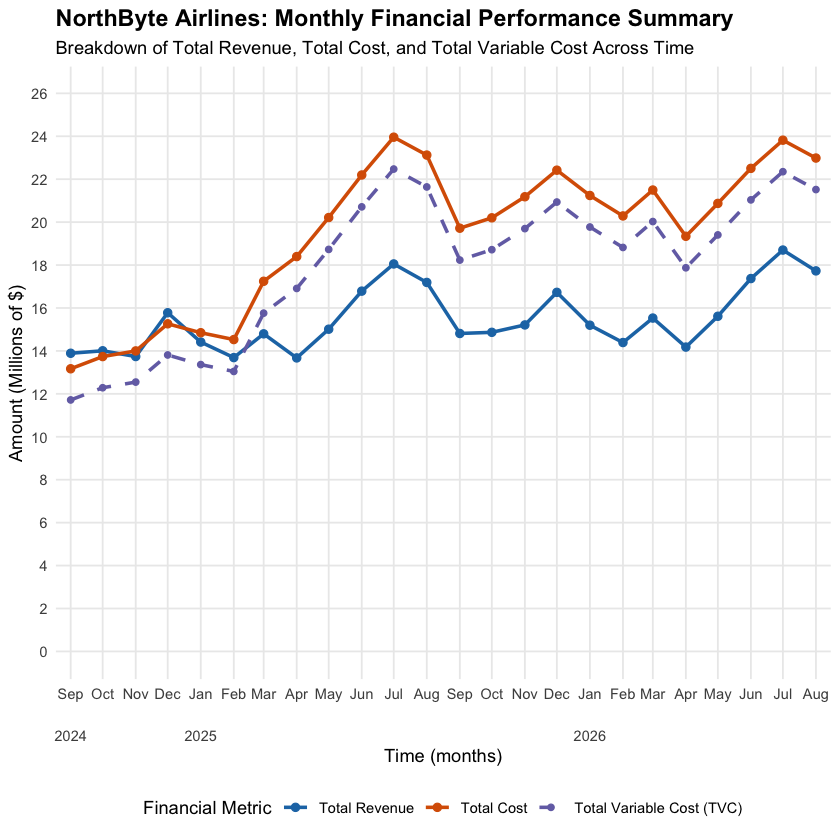

In [6]:
library(lubridate)
library(dplyr)
library(ggplot2)

# 1a. Extract monthly variable costs from costs
monthly_costs <- costs %>%
  mutate(Actual_Date = as.Date(floor_date(Cost_Date, unit = "month"))) %>%
  group_by(Actual_Date) %>%
  summarise(
    Total_Variable_Cost = sum(Amount, na.rm = TRUE),
    .groups = "drop"
  )

# 1b. Generate the monthly transaction/revenue summary dataframe
monthly_transactions <- transactions %>%
  mutate(Actual_Date = as.Date(floor_date(Transaction_Date, unit = "month"))) %>%
  group_by(Actual_Date) %>%
  summarise(
    Total_Amount = sum(Amount, na.rm = TRUE),
    # Tickets_Total_Amount = sum(Amount[Transaction_Type == "TICKET"], na.rm = TRUE),
    .groups = "drop"
  )

# 1c. Merge into a single master summary table, filter boundaries, and arrange
monthly_summary <- monthly_transactions %>%
  left_join(monthly_costs, by = "Actual_Date") %>%
  # Fill NAs with 0 if a month has transactions but no logged costs
  mutate(Total_Variable_Cost = ifelse(is.na(Total_Variable_Cost), 0, Total_Variable_Cost)) %>%
  # Filter boundaries to explicitly align with the fiscal cycle window
  filter(Actual_Date >= "2024-09-01" & Actual_Date <= "2026-08-01") %>%
  # CRITICAL: Forces chronological ordering so geom_line() connects sequentially
  arrange(Actual_Date)

# Convert raw figures to Millions ($M)
monthly_summary <- monthly_summary %>%
  mutate(
    Total_Amount_M = Total_Amount / 1000000,
    Total_Variable_Cost_M = Total_Variable_Cost / 1000000
  )

# 2. Apply your dynamic conditional fixed cost steps directly to the master table
monthly_summary <- monthly_summary %>%
  mutate(
    Year_Val = year(Actual_Date),
    Monthly_Fixed_Cost = case_when(
      Year_Val == 2024 ~ 1451941.667,
      Year_Val == 2025 ~ 1484966.667,
      Year_Val == 2026 ~ 1468454.167  # The calculated 2024-2025 average
    ),
    # Combine variable and fixed layers for absolute cost baseline
    Total_True_Cost = Total_Variable_Cost + Monthly_Fixed_Cost,
    
    # Scale values to Millions ($M)
    Monthly_Fixed_Cost_M = Monthly_Fixed_Cost / 1000000,
    Total_True_Cost_M    = Total_True_Cost / 1000000
  ) %>%
  # Clean up temporary column and order columns logically
  select(Actual_Date, Total_Amount, Total_Amount_M, 
         Total_Variable_Cost, Total_Variable_Cost_M, Monthly_Fixed_Cost, 
         Monthly_Fixed_Cost_M, Total_True_Cost, Total_True_Cost_M) %>%
  arrange(Actual_Date)

# Print the final master dataset
print(monthly_summary)

# 3. Create a clean, focused summary table including TVC
final_summary_table_M <- monthly_summary %>%
  select(
    `Month`            = Actual_Date,
    `Total Revenue $M` = Total_Amount_M,
    `Total Cost $M`    = Total_True_Cost_M,
    `Variable Cost $M` = Total_Variable_Cost_M
  )

# Print the clean master table
print(final_summary_table_M)

# 4. Render the unified three-line financial performance graph (FIXED SYNTAX)
ggplot(final_summary_table_M, aes(x = Month)) +
  
  # --- Total Revenue Line (Blue) ---
  geom_line(aes(y = `Total Revenue $M`, color = "Total Revenue"), linewidth = 1) +
  geom_point(aes(y = `Total Revenue $M`, color = "Total Revenue"), shape = 19, size = 2) +
  
  # --- Total Cost Line (Orange) ---
  geom_line(aes(y = `Total Cost $M`, color = "Total Cost"), linewidth = 1) +
  geom_point(aes(y = `Total Cost $M`, color = "Total Cost"), shape = 19, size = 2) +
  
  # --- Total Variable Cost Line (Purple / Dashed) ---
  geom_line(aes(y = `Variable Cost $M`, color = "Total Variable Cost (TVC)"), linewidth = 1, linetype = "dashed") +
  geom_point(aes(y = `Variable Cost $M`, color = "Total Variable Cost (TVC)"), shape = 19, size = 1.5) +
  
  # --- Dynamic Y-Axis Controls with Headroom Padding (Fixed \$) ---
  scale_y_continuous(
    breaks = seq(0, max(final_summary_table_M$`Total Cost $M`, na.rm = TRUE) + 4, by = 2),
    limits = c(0, max(final_summary_table_M$`Total Cost $M`, na.rm = TRUE) + 2)
  ) +
  
  # --- Standardized Chronological Timeline X-Axis (Fixed \$) ---
  scale_x_date(
    date_breaks = "1 month",
    expand = c(0.02, 0.02),
    labels = function(x) {
      ifelse(
        format(x, "%b") == "Jan" | x == min(final_summary_table_M$Month), 
        paste0(format(x, "%b"), "\n\n", format(x, "%Y")), 
        format(x, "%b")
      )
    }
  ) +
  
  # --- Explicit Palette Assignment and Custom Legend Hierarchy ---
  scale_color_manual(
    name = "Financial Metric",
    values = c(
      "Total Revenue"              = "#1f77b4",   # Trust Blue
      "Total Cost"                 = "#d95f02",   # Warning Orange
      "Total Variable Cost (TVC)"  = "#7570b3"    # Operations Purple
    ),
    breaks = c("Total Revenue", "Total Cost", "Total Variable Cost (TVC)")
  ) +
  
  # --- Labels & Theme Settings ---
  labs(
    title = "NorthByte Airlines: Monthly Financial Performance Summary",
    subtitle = "Breakdown of Total Revenue, Total Cost, and Total Variable Cost Across Time",
    x = "Time (months)",
    y = "Amount (Millions of $)"
  ) +
  theme_minimal() +
  theme(
    panel.grid.minor = element_blank(),
    axis.text.x = element_text(angle = 0, hjust = 0.5, lineheight = 1.2),
    plot.title = element_text(face = "bold", size = 14),
    legend.position = "bottom"
  )

## Question 2 - Hard
#### Statement
How does financial performance differ across NorthByte's network? Are some parts of the business carrying others?
#### Meeting Notes
**Performance across the network:** Use transaction and cost data, joined by a consistently formatted route_id, to calculate total profit and profit margin for each point-to-point route. Compare hubs with other hubs and non-hubs with other non-hubs, rather than relying only on network-wide totals. The notes also propose looking at margins across airports; how to handle connecting-route effects remained a question.
- note: can compare trips that are to a hub vs trips that just go through a hub using booking id
- profit margin might be difficult to calculate seasonally, instead just focus on profit margin by route -> individual flights being tracked seasonally is done in question 4.
#### Reasoning
#### Conclusion

In [7]:
trans_total_by_route <- transactions |> 
    group_by(Route_ID) |>
    summarize(Total_Revenue = sum(Amount))

costs_total_by_route <- costs |>
    group_by(Route_ID) |>
    summarize(Total_Cost = sum(Amount))

iata <- read_csv("airport-codes.csv")

routes_profit_margin <- trans_total_by_route |>
    inner_join(costs_total_by_route) |>
    mutate(Margin = (Total_Revenue - Total_Cost) / Total_Revenue) |>
    mutate(Departing = substr(Route_ID, 0, 3)) |>
    mutate(Arriving = substr(Route_ID, 5, 7)) |>
    left_join(iata, by = join_by(Departing == iata)) |>
    mutate(Departing_City = city) |>
    select(-city, -airport, -country)|>
    left_join(iata, by = join_by(Arriving == iata)) |>
    mutate(Arriving_City = city) |>
    select(-city, -airport, -country)|>
    arrange(desc(Margin))
routes_profit_margin
hubs <- c("YVR", "YYC", "YYZ", "YUL")

Rows: 1340 Columns: 4
── Column specification ──────────────────────────────────────────────────────────────
Delimiter: ","
chr (4): airport, city, country, iata

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Joining with `by = join_by(Route_ID)`


Route_ID,Total_Revenue,Total_Cost,Margin,Departing,Arriving,Departing_City,Arriving_City
<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
YVR-YYC,12507406.3,10015322,0.19924872,YVR,YYC,Vancouver,Calgary
YVR-YLW,5697741.9,4626212,0.18806224,YVR,YLW,Vancouver,Kelowna
YYC-YVR,13798528.0,11321595,0.17950705,YYC,YVR,Calgary,Vancouver
YQB-YUL,2782423.4,2292732,0.17599471,YQB,YUL,Quebec City,Montreal
YUL-YQB,3114585.5,2580024,0.17163179,YUL,YQB,Montreal,Quebec City
YYC-YLW,2827181.6,2349546,0.16894403,YYC,YLW,Calgary,Kelowna
YYZ-YYC,19366214.4,16341656,0.15617703,YYZ,YYC,Toronto,Calgary
YXE-YYC,3354795.5,2856052,0.14866576,YXE,YYC,Saskatoon,Calgary
YLW-YVR,5392232.0,4591485,0.14850002,YLW,YVR,Kelowna,Vancouver


In [8]:
airports_canada <- read_csv("airports-canada.csv")
locs <- iata |>
    filter(iata %in% routes_profit_margin$Departing) |>
    left_join(airports_canada, by = join_by(airport == name)) |>
    select(iata, latitude, longitude)

Rows: 500 Columns: 9
── Column specification ──────────────────────────────────────────────────────────────
Delimiter: ","
chr (4): name, country, region, feature_type
dbl (5): latitude, longitude, elevation_m, population, geoname_id

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [9]:
par(mar=c(3,3,3,3), xpd=NA)
canada <- map_data("world", region = "Canada")
margin_summary <- summary(routes_profit_margin$Margin)
connections <- routes_profit_margin |>
    inner_join(locs, by = join_by(Departing == iata)) |>
    rename(Departing_Latitude = latitude) |>
    rename(Departing_Longitude = longitude) |>
    inner_join(locs, by = join_by(Arriving == iata)) |>
    rename(Arriving_Latitude = latitude) |>
    rename(Arriving_Longitude = longitude) |> 
    mutate(Group = ifelse(
        Margin < margin_summary[2], "1st Quarter", ifelse(
            Margin < margin_summary[3], "2nd Quarter", ifelse(
                Margin < margin_summary[5], "3rd Quarter", "4th Quarter"
            )
        )
    ))
route_lines <- lapply(seq_len(nrow(connections)), function(i) {
    inter <- gcIntermediate(
        c(
            connections$Departing_Longitude[i],
            connections$Departing_Latitude[i]
        ),
        c(
            connections$Arriving_Longitude[i],
            connections$Arriving_Latitude[i]
        ),
            n = 100,
            addStartEnd = TRUE
    )
    data.frame(
        longitude = inter[, 1],
        latitude = inter[, 2],
        route = i,
        margin = connections$Margin[i],
        quarter = connections$Group[i]
    )
}) |>
    bind_rows()

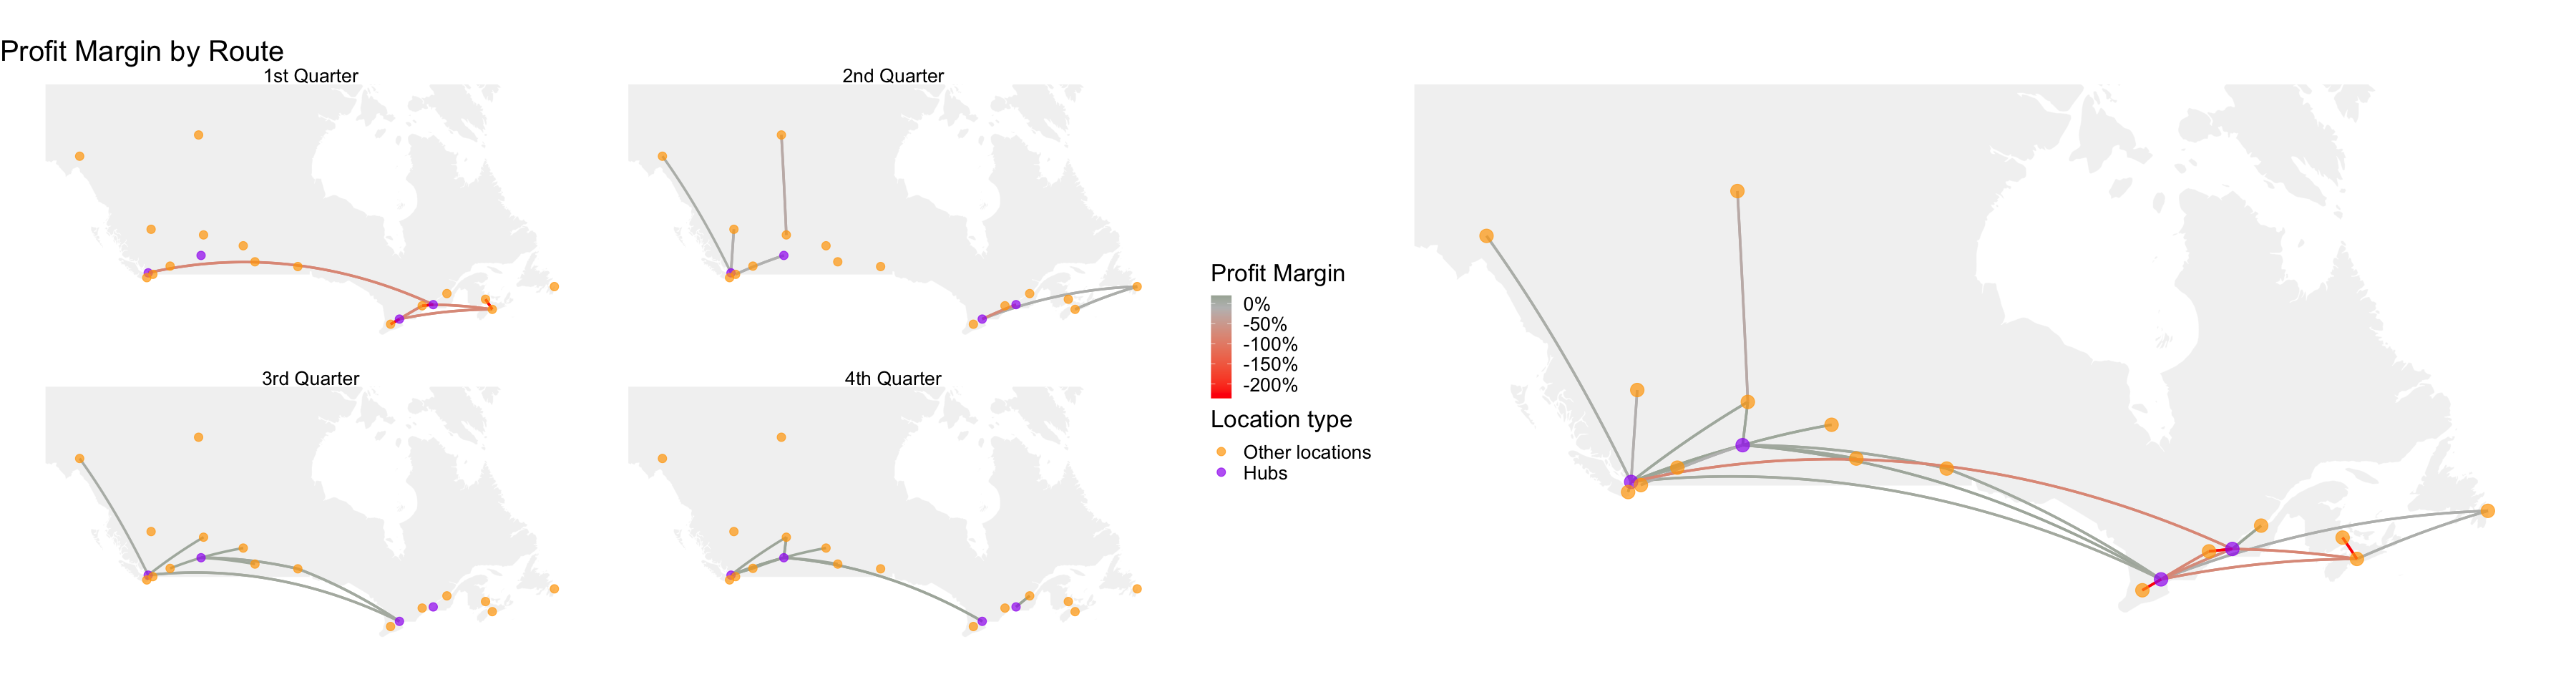

In [10]:
options(repr.plot.width=30, repr.plot.height=8)
small_multiple <- ggplot() +
    geom_polygon(
        data = canada,
        aes(x = long, y = lat, group = group),
        fill = "#f2f2f2",
        colour = "white",
        linewidth = 0.1
    ) +
    geom_path(
        data = route_lines,
        aes(x = longitude, y = latitude, color = margin, group = route),
        linewidth = 1,
        alpha = 1
    ) +
    scale_colour_gradient2(
        low = "red",
        mid = "grey",
        high = "darkgreen",
        midpoint = -0.10,
        name = "Profit Margin",
        labels = scales::label_percent()
    ) +
    new_scale_color() +
    geom_point(
        data = locs,
        aes(
            x = longitude,
            y = latitude,
            color = iata %in% hubs
        ),
        alpha = 0.7,
        size = 3
    ) +
    scale_color_manual(
        values = c("FALSE" = "orange", "TRUE" = "purple"),
        labels = c("FALSE" = "Other locations", "TRUE" = "Hubs"),
        name = "Location type"
    ) +
    coord_map(
        projection = "mercator",
        xlim = c(-140, -50),
        ylim = c(40, 65)
    ) +
    facet_wrap(~ quarter) +
    theme_void(base_size=20)
large <- ggplot() +
    geom_polygon(
        data = canada,
        aes(x = long, y = lat, group = group),
        fill = "#f2f2f2",
        colour = "white",
        linewidth = 0.1
    ) +
    geom_path(
        data = route_lines,
        aes(x = longitude, y = latitude, color = margin, group = route),
        linewidth = 1,
        alpha = 1
    ) +
    scale_colour_gradient2(
        low = "red",
        mid = "grey",
        high = "darkgreen",
        midpoint = -0.10,
        name = "Profit Margin",
        guide = "none"
    ) +
    new_scale_color() +
    geom_point(
        data = locs,
        aes(
            x = longitude,
            y = latitude,
            color = iata %in% hubs
        ),
        alpha = 0.7,
        size = 5
    ) +
    scale_color_manual(
        values = c("FALSE" = "orange", "TRUE" = "purple"),
        labels = c("FALSE" = "Other locations", "TRUE" = "Hubs"),
        name = "Location type",
        guide = "none"
    ) +
    coord_map(
        projection = "mercator",
        xlim = c(-140, -50),
        ylim = c(40, 65)
    ) +
    theme_void(base_size=20)

(small_multiple + large) +
plot_annotation("Profit Margin by Route", theme = theme_void(base_size=20))

# group by arriving, average using modified lollipop chart
#ggplot(routes_profit_margin)
# small multiple routes by profitabililty
# also separate routes by number of flights

In [ ]:
city_labels <- routes_profit_margin |>
    distinct(Departing, Departing_City) |>
    mutate(
        label = if_else(
        Departing %in% hubs,
        paste0("<span style='color:purple;'>", Departing_City, "</span>"),
        Departing_City
    )
)
routes_profit_margin <- routes_profit_margin |>
    group_by(Departing_City) |>
    mutate(median_margin = median(Margin))
worst_style <- list(
  alpha = 0.3,
  fill = "bisque"
)
bad_style <- list(
  alpha = 0.3,
  fill = "darkolivegreen1"
)

count_tickets <- transactions |>
    filter(Transaction_Type == "TICKET") |>
    inner_join(routes_profit_margin, by=join_by(Route_ID)) |>
    group_by(Route_ID) |>
    summarize(Tickets_Count = n())

count_flights <- costs |>
    filter(Cost_Type == "Fuel") |>
    inner_join(routes_profit_margin, by=join_by(Route_ID)) |>
    group_by(Route_ID) |>
    summarize(Flights_Count = n())

routes_profit_margin_with_tickets <- inner_join(routes_profit_margin, count_tickets, by=join_by(Route_ID))
routes_profit_margin_with_tickets <- inner_join(routes_profit_margin, count_flights, by=join_by(Route_ID))
routes_profit_margin_with_tickets

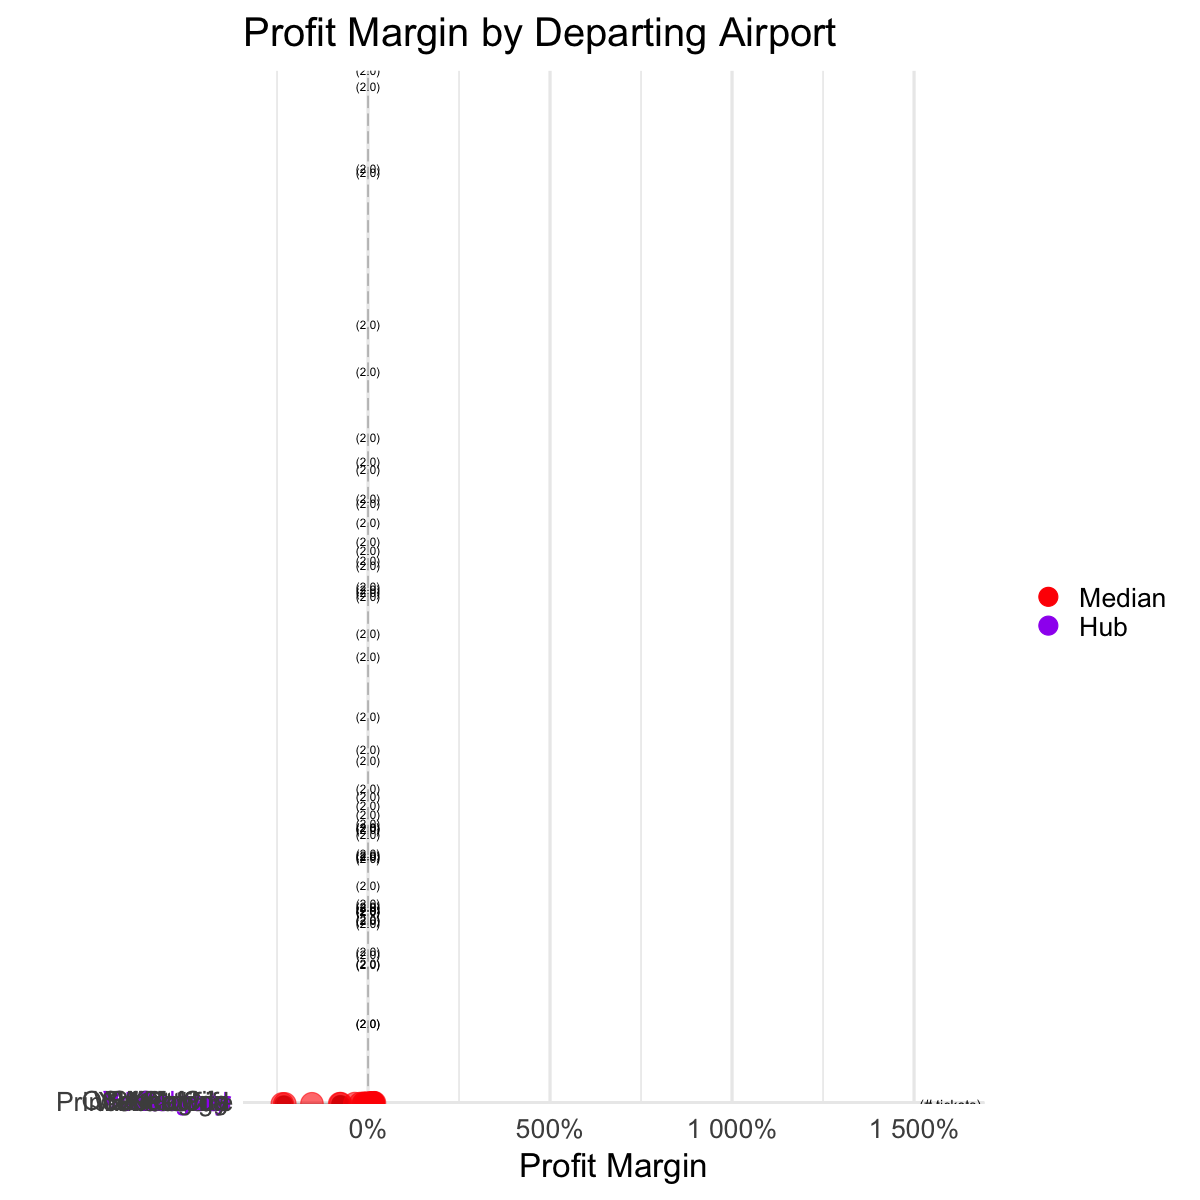

In [12]:
options(repr.plot.width = 10, repr.plot.height = 10)
graph_routes_profit_margin <- ggplot(routes_profit_margin, aes(x = Margin, y = reorder(Departing_City, median_margin), group = Departing_City)) +
    geom_segment(aes(x = 0, xend = Margin, yend = Departing_City), alpha = 0.4, color = "gray") +
    annotate("text", x = 16, y = 0, label = "(# tickets)", size = 3, hjust = 0.5) +
    stat_summary(
        data = count_tickets,
        aes(y = Tickets_Count, x = 2),
        geom = "text",
        fun.data = function(x) {
            data.frame(
                y = 0,
                label = sprintf("(%s)", scales::number(mean(ifelse(x > 0, x, NA), na.rm = TRUE), accuracy = 0.1)))},
        size = 2.5,
        inherit.aes = FALSE
    ) +
    annotate("rect", xmin = -2.50, xmax = -2.10, ymin = 0.5, ymax = 6.5, alpha = worst_style$alpha, fill = worst_style$fill) +
    annotate("rect", xmin = -0.9, xmax = -0.6, ymin = 2.3, ymax = 13.7, alpha = bad_style$alpha, fill = bad_style$fill) +
    geom_vline(xintercept = 0, color = "gray", linetype="longdash") +
    geom_point(alpha = 0.3, size = 4) +
    geom_point(data = routes_profit_margin |>
            distinct(median_margin),
        aes(x = median_margin, color = "Median"), size = 6, alpha = 0.6
    ) +
    geom_point(
    data = routes_profit_margin |>
            filter(Departing %in% hubs),
        aes(x = Margin, y = Departing_City, color = "Hub"),
        alpha = 0
    ) +
    scale_color_manual(
        name = "",
        values = c("Median" = "red", "Hub" = "purple"),
        breaks = c("Median", "Hub"),
    ) +
    guides(color = guide_legend(override.aes = list(alpha = 1, size = 5))) +
    scale_x_continuous(labels=scales::percent) +
    scale_y_discrete(labels = setNames(city_labels$label, city_labels$Departing_City)) +
    theme_minimal(base_size = 20) +
    theme(axis.text.y = ggtext::element_markdown()) +
    ylab("") +
    xlab("Profit Margin") +
    ggtitle("Profit Margin by Departing Airport")
graph_routes_profit_margin

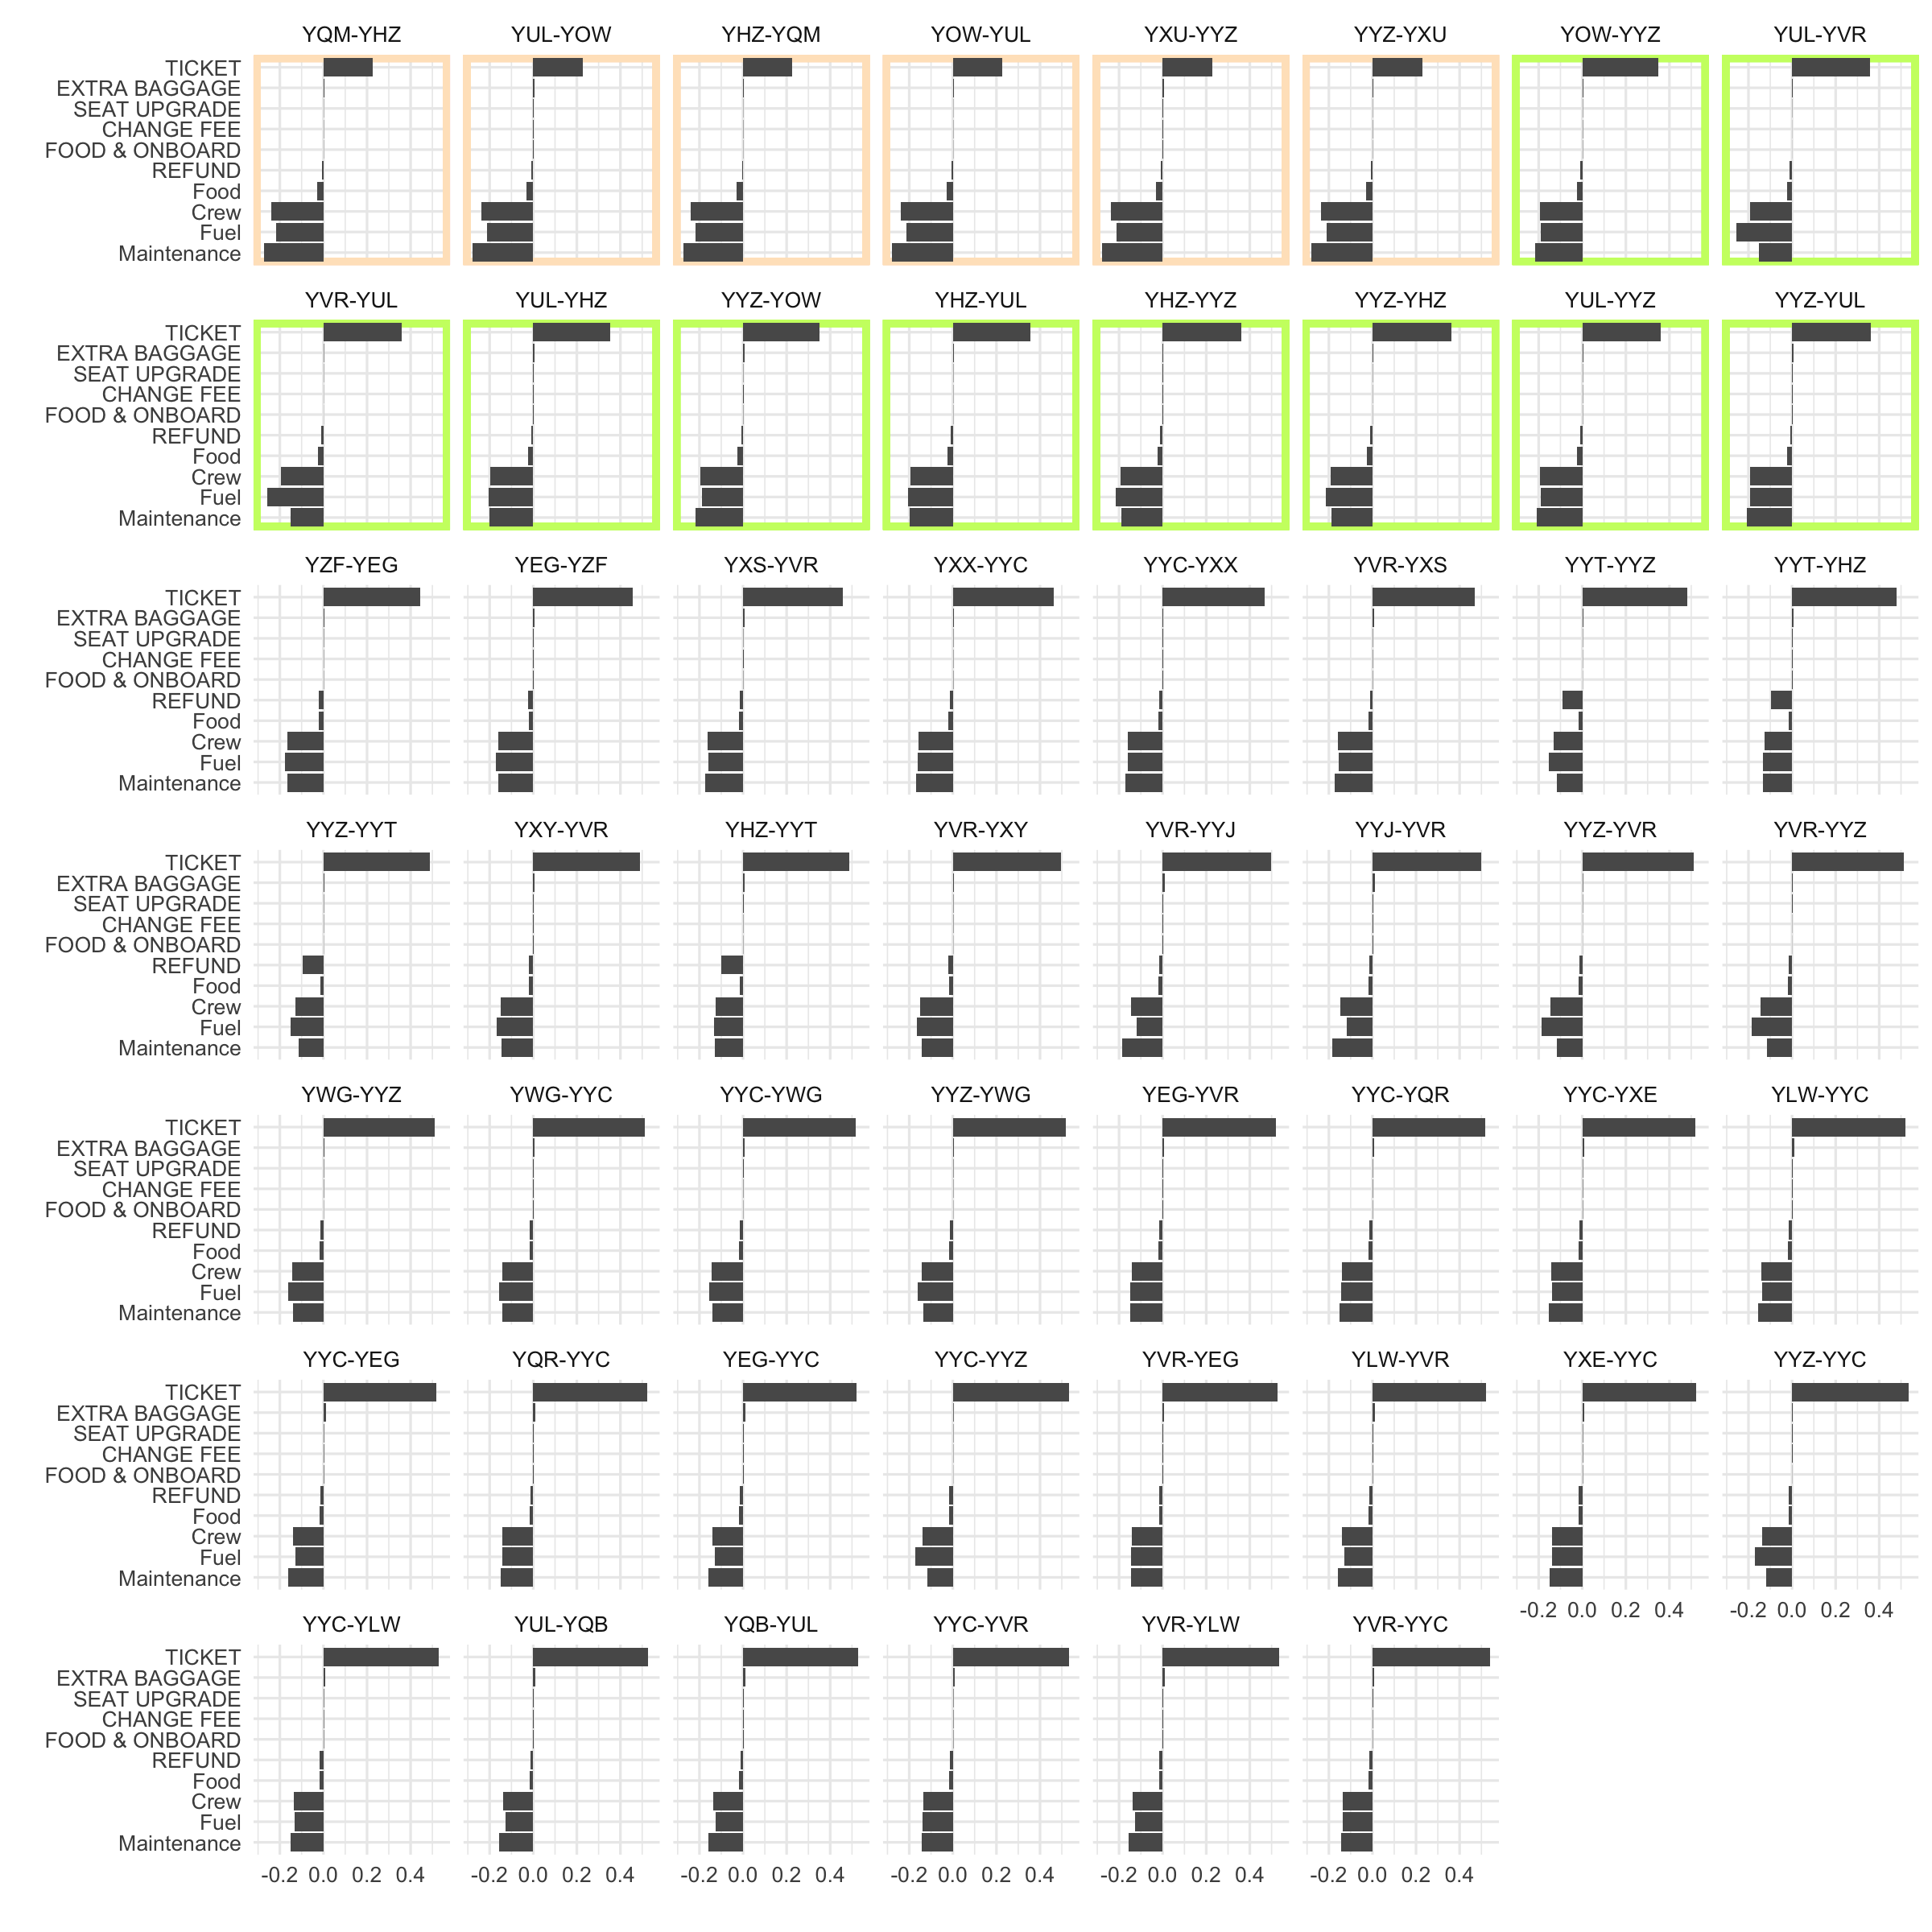

In [13]:
options(repr.plot.width = 20, repr.plot.height = 20)
worst_routes <- routes_profit_margin |>
    ungroup() |>
    filter(Margin < -2) |>
    select(Route_ID)
bad_routes <- routes_profit_margin |>
    ungroup() |>
    filter(Margin > -1 & Margin < -0.5) |>
    select(Route_ID)
routes_grouped_costs <- costs |>
    group_by(Route_ID, Cost_Type) |>
    summarize(Total = sum(Amount) * -1, .groups = "drop") |>
    inner_join(
        routes_profit_margin |>
            ungroup() |>
            select(Route_ID, Margin),
            by = "Route_ID"
        )
routes_grouped_transactions <- transactions |>
    group_by(Route_ID, Transaction_Type) |>
    summarize(Total = sum(Amount), .groups = "drop") |>
    inner_join(
        routes_profit_margin |>
            ungroup() |>
            select(Route_ID, Margin),
            by = "Route_ID"
        ) |>
    rename(Cost_Type = Transaction_Type)
routes_grouped <- bind_rows(routes_grouped_costs, routes_grouped_transactions) |>
    group_by(Route_ID) |>
    mutate(Total = Total / sum(abs(Total))) |>
    mutate(group = ifelse(Route_ID %in% worst_routes$Route_ID, "worst", ifelse(Route_ID %in% bad_routes$Route_ID, "bad", "none")))
graph_routes_grouped_costs <- ggplot(
  routes_grouped,
  aes(x = Total, y = fct_reorder(Cost_Type, Total, .fun = mean))
) +
  geom_rect(
    data = routes_grouped |>
      filter(group == "worst"),
    aes(
      xmin = -Inf, xmax = Inf,
      ymin = -Inf, ymax = Inf,
      group = Route_ID
    ),
    color = worst_style$fill,
    fill = NA,
    linewidth = 5,
    inherit.aes = FALSE
  ) +
  geom_rect(
    data = routes_grouped |>
      filter(group == "bad"),
    aes(
      xmin = -Inf, xmax = Inf,
      ymin = -Inf, ymax = Inf,
      group = Route_ID
    ),
    color = bad_style$fill,
    fill = NA,
    linewidth = 5,
    inherit.aes = FALSE
  ) +
  geom_col() +
  facet_wrap(~ forcats::fct_reorder(Route_ID, Margin)) +
  labs(x = "", y = "") +
  theme_minimal(base_size = 20)
graph_routes_grouped_costs

## Question 3 - Moderate
#### Statement
How much do rising fuel and crew costs, refunds, and the NorthByte Rewards program contribute to the decline? Which factors matter most?
#### Meeting Notes
**Fuel, crew, refunds, and rewards:** Examine how rising fuel and crew costs, refunds, and the rewards program contributed to the decline. For rewards, compare ticket transactions and redemptions by membership tier, using non-members as a baseline. The team noted that the data did not identify individual customers or specify the thresholds for entering each tier, limiting more detailed conclusions.
#### Conclusion

## Question 4 - Hard
#### Statement
What role do ancillary revenue, refunds, and connecting passengers play in how NorthByte earns its money?
#### Meeting Notes
**Ancillary revenue, refunds, and connecting passengers:** Separate revenue such as food and extra-baggage fees from refunds and connecting-ticket revenue. Use booking IDs to identify connections, then compare ticket revenue against per-flight fuel, crew, food, and maintenance costs—potentially by airport. The team also proposed checking dates for seasonal changes in fuel, maintenance, cancellations, and refunds before considering seasonal flight-frequency changes.
- graph how profitable each individual flight is by when it happens, maybe flights during the winter on average result in a loss
  - then group by airport (small-multiple graph?)
- note that gate lease is yearly
#### Conclusion

## Question 5 - Easy
#### Statement
How did NorthByte's gate lease costs change from the 2024-2025 lease year to the 2025-2026 lease year? Based on these trends, what would you expect NorthByte to pay for its gates in 2026-2027?
#### Meeting Notes
**Gate leases:** Compare gate lease costs from 2024–25 to 2025–26, then project 2026–27 costs from that trend. The team discussed an increase of roughly 2%, but flagged that the projection must state an assumption about whether the number of gates stays the same; the later-year gate data was unavailable.
#### Conclusion